# SME Financial Risk and Business Intelligence Analysis

An end-to-end analysis of 350 synthetic small and medium enterprises (SMEs): data cleaning, exploration, feature engineering, a modelling test and a rule-based risk scorecard.

**Results at a glance**

- **Cleaning.** 350 raw records became 328 analysis records. The issue log in section 2 lists 14 problems, each with a row count. 5 near-duplicates were removed and 17 records outside the SME definition went to a separate file.
- **Losses and leverage.** 114 of 328 SMEs (34.8%) made a loss. 60 firms (18.3%) have debt-to-equity above 2.
- **Risk tiers.** A two-signal scorecard puts 178 firms in Green, 126 in Amber and 24 in Red.
- **Prediction.** Models built on non-profit features did not predict losses. The best mean ROC-AUC was 0.551, against 0.500 for a model with no information.
- **Group differences.** The gaps I tested by sector, company size and digital adoption were not distinguishable from chance.
- **A warning.** Adding one profit-based column lifts AUC from 0.513 to 0.995. That jump is leakage, not skill.

**About the data.** The records are synthetic. A script (`src/generate_sme_data.py`) builds them and plants defects on purpose: missing values, outliers, mixed formats, near-duplicates and invalid rows. The cleaning work is real. The business patterns are not, because the generator draws most fields independently. I say so wherever it affects a conclusion.

## 0. Setup

In [1]:
import json
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display
from scipy import stats

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

DATA_DIR = Path("../data")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

REFERENCE_YEAR = 2025   # year used to derive years_in_operation when the data was generated
SEED = 42
np.random.seed(SEED)

PALETTE = ["#264653", "#2a9d8f", "#e9c46a", "#f4a261", "#e76f51"]
TIER_COLORS = {"Green": "#2a9d8f", "Amber": "#e9c46a", "Red": "#e63946"}
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 160)
print("Setup complete.")

Setup complete.


## 1. Load and inspect the raw data

In [2]:
raw = pd.read_csv(DATA_DIR / "sme_dataset.csv", dtype={"founding_year": str})
print(f"{raw.shape[0]} rows x {raw.shape[1]} columns")
raw.head()

350 rows x 30 columns


,sme_id,business_name,city,state,founding_year,industry_sector,employee_count,business_structure,years_in_operation,remote_workers_percentage,annual_revenue,annual_profit,profit_margin,monthly_cash_flow,total_assets,total_liabilities,debt_to_equity_ratio,num_products_services,avg_customer_rating,social_media_followers,website_exists,export_products,digital_adoption_level,founded_during_recession,has_loan_outstanding,loan_amount,num_competitors_in_region,sustainability_certified,last_financial_update,notes
0,SME-0001,"Terra Consulting, Inc.",Chicago,IL,2013,Manufacturing,55,Corporation,12,24.6,1978305.75,41897.54,0.0212,2841.74,3922222.63,2820385.19,2.5597,6,1.7,10955,Yes,No,High,No,No,NaN,24,NaN,Mar 2024,Suply chain delays.
1,SME-0002,Bright Enterprises & Partners,Kansas City,MO,06,Retail,116,Partnership,19,9.6,4475997.02,1573367.30,0.3515,150268.38,7754356.98,3266398.40,0.7278,19,3.3,3193,No,No,Low,No,No,NaN,0,No,Sep 2023,Compliance audit due.
2,SME-0003,SummitHub Pvt Ltd,Omaha,NE,1991,Retail,66,Private Limited,34,44.2,1603109.91,124826.49,0.0779,9842.10,1532935.92,753033.88,0.9655,40,4.0,8240,Yes,Yes,med,Yes,Yes,1814629.08,24,No,12/09/2024,Exp staff turnover issues.
3,SME-0004,Orbit Solutions & Partners,Seattle,WA,2023,Retail,60,Partnership,-5,80.8,1169980.76,-262359.73,-0.2242,-23254.17,630095.53,497135.59,3.7390,44,NaN,72676,No,Yes,Medium,No,No,NaN,18,No,2024,Owner plans to retire soon.
4,SME-0005,King Enterprises & Partners,Jacksonville,FL,2000,Technology,60,Partnership,33,41.4,1763105.50,662735.60,0.3759,64476.70,2028264.00,465126.67,0.2976,6,2.1,721,Yes,No,Medium,No,Yes,1228600.42,16,No,11-01-2021,TBD


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   sme_id                     350 non-null    str    
 1   business_name              350 non-null    str    
 2   city                       350 non-null    str    
 3   state                      350 non-null    str    
 4   founding_year              350 non-null    str    
 5   industry_sector            350 non-null    str    
 6   employee_count             350 non-null    int64  
 7   business_structure         350 non-null    str    
 8   years_in_operation         350 non-null    int64  
 9   remote_workers_percentage  310 non-null    float64
 10  annual_revenue             350 non-null    float64
 11  annual_profit              350 non-null    float64
 12  profit_margin              301 non-null    float64
 13  monthly_cash_flow          350 non-null    float64
 14  total

In [4]:
missing = raw.isna().sum()
(pd.DataFrame({"missing": missing, "pct": (missing / len(raw) * 100).round(1)})
   .query("missing > 0")
   .sort_values("pct", ascending=False))

,missing,pct
loan_amount,85,24.3
profit_margin,49,14.0
avg_customer_rating,46,13.1
notes,44,12.6
remote_workers_percentage,40,11.4
sustainability_certified,12,3.4


`loan_amount` is blank for firms with no loan. That is not a data gap. I handle it in section 2.

## 2. Clean the data

Every step writes to an issue log with a row count. The summary table at the end of this section comes from that log, so the totals always match the data.

### 2.1 Near-duplicate records

A near-duplicate is the same business entered twice. Here the copies differ only in the id, the spelling of the name and a small change in headcount. Business names are unique in this file, so I match on every other column instead.

In [5]:
issue_log = []


def log_issue(issue, rows, action):
    issue_log.append({"issue": issue, "rows_affected": int(rows), "action": action})


df = raw.copy()

key_cols = [c for c in df.columns if c not in ("sme_id", "business_name", "employee_count")]
in_a_pair = df.duplicated(subset=key_cols, keep=False)
(df[in_a_pair]
   .sort_values(["city", "annual_revenue", "sme_id"])
   [["sme_id", "business_name", "employee_count", "city", "industry_sector", "annual_revenue"]])

,sme_id,business_name,employee_count,city,industry_sector,annual_revenue
174,SME-0175,"Delta Works, Inc.",13,Indianapolis,Agriculture,771747.14
319,SME-0320,Delta Works Inc.,12,Indianapolis,Agriculture,771747.14
315,SME-0316,XcelPartners Pvt Ltd,75,Memphis,Healthcare,2566596.56
348,SME-0349,XCELPARTNERS PVT LTD,76,Memphis,Healthcare,2566596.56
86,SME-0087,Bright Systems,81,Milwaukee,Construction,4299807.77
346,SME-0347,The Bright Systems,79,Milwaukee,Construction,4299807.77
98,SME-0099,BLUEGROUP,94,Sacramento,Hospitality,2630380.87
317,SME-0318,BlueGroup,93,Sacramento,Hospitality,2630380.87
266,SME-0267,"Dawn Consulting, Inc.",21,Tucson,Professional Services,664455.83
342,SME-0343,"Dawn Consulting, Inc",20,Tucson,Professional Services,664455.83


In [6]:
is_copy = df.duplicated(subset=key_cols, keep="first")
log_issue("Near-duplicate records (same data, different name spelling and headcount)",
          is_copy.sum(), "Kept the first record of each pair and dropped the other")
df = df[~is_copy].reset_index(drop=True)
print(f"Removed {is_copy.sum()} duplicates. Rows left: {len(df)}")

Removed 5 duplicates. Rows left: 345


### 2.2 Founding year and years in operation

`founding_year` appears as `2001`, `01` or `2001-01-01`. Every year in the file falls between 1980 and 2024, so a two-digit value of 24 or below means 20xx and a higher value means 19xx.

In [7]:
def clean_founding_year(value):
    value = str(value).strip()
    if re.fullmatch(r"\d{4}-\d{2}-\d{2}", value):
        return int(value[:4])
    if re.fullmatch(r"\d{2}", value):
        year = int(value)
        return 2000 + year if year <= 24 else 1900 + year
    if re.fullmatch(r"\d{4}", value):
        return int(value)
    return np.nan


not_four_digits = (~df["founding_year"].astype(str).str.fullmatch(r"\d{4}")).sum()
df["founding_year"] = df["founding_year"].apply(clean_founding_year).astype("Int64")
assert df["founding_year"].between(1980, 2024).all()
log_issue("founding_year stored as a 2-digit year or a full date", not_four_digits,
          "Converted to a 4-digit integer year")

expected_years = REFERENCE_YEAR - df["founding_year"]
wrong_years = df["years_in_operation"] != expected_years
print(f"years_in_operation wrong in {wrong_years.sum()} rows: "
      f"{(df['years_in_operation'] < 0).sum()} negative, "
      f"{(df['years_in_operation'] > expected_years).sum()} too long")
log_issue(f"years_in_operation does not equal {REFERENCE_YEAR} minus founding_year", wrong_years.sum(),
          "Recalculated from founding_year")
df["years_in_operation"] = expected_years.astype(int)

years_in_operation wrong in 26 rows: 13 negative, 13 too long


### 2.3 Categories, free text and dates

In [8]:
adoption_map = {"low": "Low", "med": "Medium", "medium": "Medium", "high": "High"}
spellings = df["digital_adoption_level"].nunique()
standard = df["digital_adoption_level"].str.strip().str.lower().map(adoption_map)
assert standard.notna().all()
log_issue(f"digital_adoption_level written {spellings} different ways for 3 categories",
          (df["digital_adoption_level"] != standard).sum(), "Mapped to Low, Medium or High")
df["digital_adoption_level"] = standard
df["digital_adoption_level"].value_counts()

digital_adoption_level
Medium    160
Low       114
High       71
Name: count, dtype: int64

In [9]:
placeholders = {"tbd", "n/a", "na", ""}
is_placeholder = df["notes"].fillna("").str.strip().str.lower().isin(placeholders)
log_issue("notes holds a placeholder such as TBD", (df["notes"].notna() & is_placeholder).sum(),
          "Set to missing")
df["notes"] = df["notes"].where(~is_placeholder)

DATE_RULES = [
    (r"\d{4}-\d{2}-\d{2}", "%Y-%m-%d", "day", "YYYY-MM-DD"),
    (r"\d{2}/\d{2}/\d{4}", "%d/%m/%Y", "day", "DD/MM/YYYY"),
    (r"\d{2}-\d{2}-\d{4}", "%m-%d-%Y", "day", "MM-DD-YYYY"),
    (r"[A-Za-z]{3} \d{4}", "%b %Y", "month", "Mon YYYY"),
    (r"\d{4}", "%Y", "year", "YYYY"),
]


def parse_update(value):
    value = str(value).strip()
    for pattern, fmt, precision, label in DATE_RULES:
        if re.fullmatch(pattern, value):
            return pd.to_datetime(value, format=fmt), precision, label
    return pd.NaT, "unknown", "unknown"


parsed = [parse_update(v) for v in df["last_financial_update"]]
df["last_financial_update_date"] = pd.to_datetime([p[0] for p in parsed])
df["last_update_precision"] = [p[1] for p in parsed]
formats = pd.Series([p[2] for p in parsed])
assert df["last_financial_update_date"].notna().all()
log_issue("last_financial_update written in five date formats", (formats != "YYYY-MM-DD").sum(),
          "Parsed to a date. Month-only and year-only values use the first day and are flagged in last_update_precision")
formats.value_counts().rename("rows").to_frame()

,rows
YYYY,77
YYYY-MM-DD,71
DD/MM/YYYY,68
MM-DD-YYYY,65
Mon YYYY,64


The date rule is an assumption. A slash is read as day first and a dash as month first, which matches how this file was generated. With real data I would confirm the rule with each source system.

### 2.4 Reconcile derived fields

Profit margin and debt-to-equity are calculated fields. When a stored value disagrees with the figures it comes from, I trust the source columns (profit, revenue, assets and liabilities) and recalculate.

In [10]:
computed_margin = df["annual_profit"] / df["annual_revenue"]
margin_missing = df["profit_margin"].isna()
margin_wrong = df["profit_margin"].notna() & ((df["profit_margin"] - computed_margin).abs() > 0.001)
sign_conflict = margin_wrong & (df["profit_margin"] < 0) & (df["annual_profit"] > 0)
log_issue("profit_margin missing", margin_missing.sum(), "Recalculated as annual_profit / annual_revenue")
log_issue(f"profit_margin disagrees with profit / revenue ({sign_conflict.sum()} show a negative margin with a positive profit)",
          margin_wrong.sum(), "Recalculated as annual_profit / annual_revenue")
df["profit_margin"] = computed_margin.round(4)

equity = df["total_assets"] - df["total_liabilities"]
assert (equity > 0).all()
computed_de = df["total_liabilities"] / equity
de_wrong = (df["debt_to_equity_ratio"] - computed_de).abs() > 0.001
zero_de = de_wrong & (df["debt_to_equity_ratio"] == 0) & (df["total_liabilities"] > 0)
huge_de = de_wrong & (df["debt_to_equity_ratio"] > 5)
log_issue(f"debt_to_equity_ratio does not match the balance sheet ({zero_de.sum()} are 0 with liabilities above 0, {huge_de.sum()} are above 5)",
          de_wrong.sum(), "Recalculated as total_liabilities / (total_assets - total_liabilities)")
df["debt_to_equity_ratio"] = computed_de.round(4)
print(f"Largest debt-to-equity after reconciling: {df['debt_to_equity_ratio'].max():.2f}")

Largest debt-to-equity after reconciling: 3.84


### 2.5 Loans

A firm with no loan has no loan balance, so the blank in `loan_amount` means zero.

In [11]:
no_loan = df["has_loan_outstanding"] == "No"
blank_no_loan = (no_loan & df["loan_amount"].isna()).sum()
print(f"Firms with no loan: {no_loan.sum()}")
print(f"  loan_amount blank: {blank_no_loan} | already zero: {(no_loan & (df['loan_amount'] == 0)).sum()} | above zero: {(no_loan & (df['loan_amount'] > 0)).sum()}")
print(f"Firms with a loan but no amount: {(~no_loan & df['loan_amount'].isna()).sum()}")
assert df.loc[~no_loan, "loan_amount"].notna().all()
log_issue("loan_amount blank for firms with no loan (not a real gap)", blank_no_loan, "Set to 0")
df.loc[no_loan, "loan_amount"] = 0.0

Firms with no loan: 131
  loan_amount blank: 85 | already zero: 46 | above zero: 0
Firms with a loan but no amount: 0


### 2.6 Records outside the SME definition

The data specification describes SMEs as firms with 5 to 250 employees and revenue up to $15 million. Records above those limits are not SMEs, so I move them to a separate file with the reason. I do not cap them, because capping revenue would leave profit, assets and liabilities out of step with it.

In [12]:
over_staffed = df["employee_count"] > 250
over_revenue = df["annual_revenue"] > 15_000_000
out_of_scope = over_staffed | over_revenue
reason = np.select(
    [over_staffed, over_revenue & (df["employee_count"] <= 10)],
    ["employee_count above 250", "revenue above $15M with 10 or fewer staff"],
    default="revenue above $15M",
)
excluded = df[out_of_scope].assign(exclusion_reason=reason[out_of_scope.to_numpy()])
excluded.to_csv(DATA_DIR / "sme_excluded_records.csv", index=False)
log_issue("Records outside the SME definition (over 250 staff or over $15M revenue)", out_of_scope.sum(),
          "Moved to data/sme_excluded_records.csv with the reason")
df = df[~out_of_scope].reset_index(drop=True)
print(excluded["exclusion_reason"].value_counts().to_string())
print(f"Rows kept: {len(df)}")

exclusion_reason
revenue above $15M with 10 or fewer staff    7
revenue above $15M                           6
employee_count above 250                     4
Rows kept: 328


### 2.7 Remaining missing values

Rating and remote share are missing for roughly one firm in eight. I fill them with the median and keep a flag column so the filled rows stay visible. Missing sustainability status becomes its own category, because a missing value does not mean "not certified".

In [13]:
for col in ["avg_customer_rating", "remote_workers_percentage"]:
    n_missing = df[col].isna().sum()
    median = df[col].median()
    df[f"{col}_was_missing"] = df[col].isna().astype(int)
    df[col] = df[col].fillna(median)
    log_issue(f"{col} missing", n_missing, f"Filled with the median ({median:.1f}) and flagged")

n_unknown = df["sustainability_certified"].isna().sum()
df["sustainability_certified"] = df["sustainability_certified"].fillna("Unknown")
log_issue("sustainability_certified missing", n_unknown, "Set to the category Unknown")

### 2.8 Final checks and issue log

In [14]:
check_cols = [c for c in df.columns if c != "notes"]
assert not df[check_cols].isna().any().any(), "Missing values remain"
assert df["sme_id"].is_unique
print(f"Raw rows: {len(raw)} -> clean rows: {len(df)}")
df[["employee_count", "annual_revenue", "profit_margin", "debt_to_equity_ratio", "years_in_operation"]].describe().round(2)

Raw rows: 350 -> clean rows: 328


,employee_count,annual_revenue,profit_margin,debt_to_equity_ratio,years_in_operation
count,328.00,328.00,328.00,328.00,328.00
mean,62.15,2070272.57,0.11,1.15,23.76
std,62.88,2529792.36,0.20,0.95,13.13
min,5.00,53678.29,-0.25,0.11,1.00
25%,18.00,517559.25,-0.08,0.39,13.00
50%,40.00,1168824.54,0.12,0.85,24.00
75%,81.00,2380091.06,0.30,1.67,35.00
max,250.00,14990144.29,0.45,3.84,45.00


In [15]:
pd.DataFrame(issue_log)

,issue,rows_affected,action
0,"Near-duplicate records (same data, different name spelling and headcount)",5,Kept the first record of each pair and dropped the other
1,founding_year stored as a 2-digit year or a full date,21,Converted to a 4-digit integer year
2,years_in_operation does not equal 2025 minus founding_year,26,Recalculated from founding_year
3,digital_adoption_level written 11 different ways for 3 categories,91,"Mapped to Low, Medium or High"
4,notes holds a placeholder such as TBD,19,Set to missing
5,last_financial_update written in five date formats,274,Parsed to a date. Month-only and year-only values use the first day and are flagged in last_update_precision
6,profit_margin missing,47,Recalculated as annual_profit / annual_revenue
7,profit_margin disagrees with profit / revenue (21 show a negative margin with a positive profit),30,Recalculated as annual_profit / annual_revenue
8,"debt_to_equity_ratio does not match the balance sheet (11 are 0 with liabilities above 0, 18 are above 5)",29,Recalculated as total_liabilities / (total_assets - total_liabilities)
9,loan_amount blank for firms with no loan (not a real gap),85,Set to 0


In [16]:
df.to_csv(DATA_DIR / "sme_cleaned.csv", index=False)
print("Saved data/sme_cleaned.csv")

Saved data/sme_cleaned.csv


## 3. Explore the data

In [17]:
df["sme_size"] = pd.cut(df["employee_count"], bins=[0, 9, 49, 250],
                        labels=["Micro (<10)", "Small (10-49)", "Medium (50-250)"]).astype(str)
SIZE_ORDER = ["Micro (<10)", "Small (10-49)", "Medium (50-250)"]
df["sme_size"].value_counts().reindex(SIZE_ORDER).rename("firms").to_frame()

,firms
sme_size,
Micro (<10),35
Small (10-49),153
Medium (50-250),140


### 3.1 Sectors

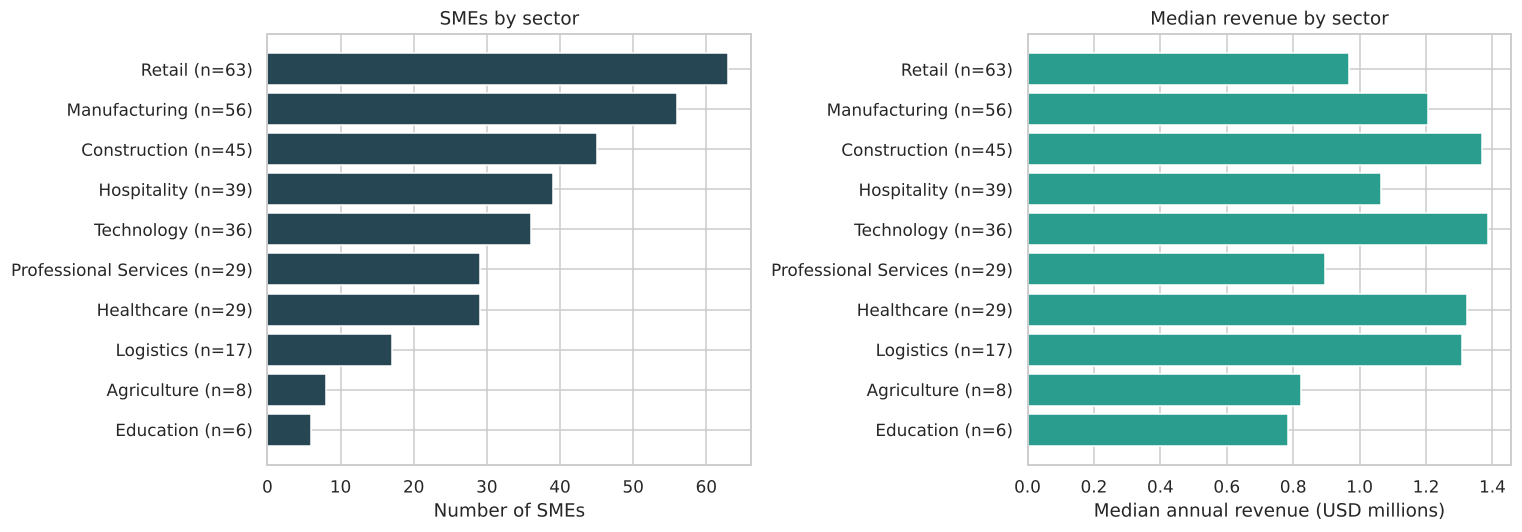

,firms,median_revenue
industry_sector,,
Retail,63,966908.0
Manufacturing,56,1206114.0
Construction,45,1369432.0
Hospitality,39,1065149.0
Technology,36,1387652.0
Healthcare,29,1321933.0
Professional Services,29,894717.0
Logistics,17,1308071.0
Agriculture,8,824445.0


In [18]:
sector = (df.groupby("industry_sector")
            .agg(firms=("sme_id", "count"), median_revenue=("annual_revenue", "median"))
            .sort_values("firms"))
labels = [f"{s} (n={n})" for s, n in zip(sector.index, sector["firms"])]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(labels, sector["firms"], color=PALETTE[0])
axes[0].set_xlabel("Number of SMEs")
axes[0].set_title("SMEs by sector")
axes[1].barh(labels, sector["median_revenue"] / 1e6, color=PALETTE[1])
axes[1].set_xlabel("Median annual revenue (USD millions)")
axes[1].set_title("Median revenue by sector")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_sector_overview.png", bbox_inches="tight")
plt.show()
sector.sort_values("firms", ascending=False).round(0)

### 3.2 Revenue and profit

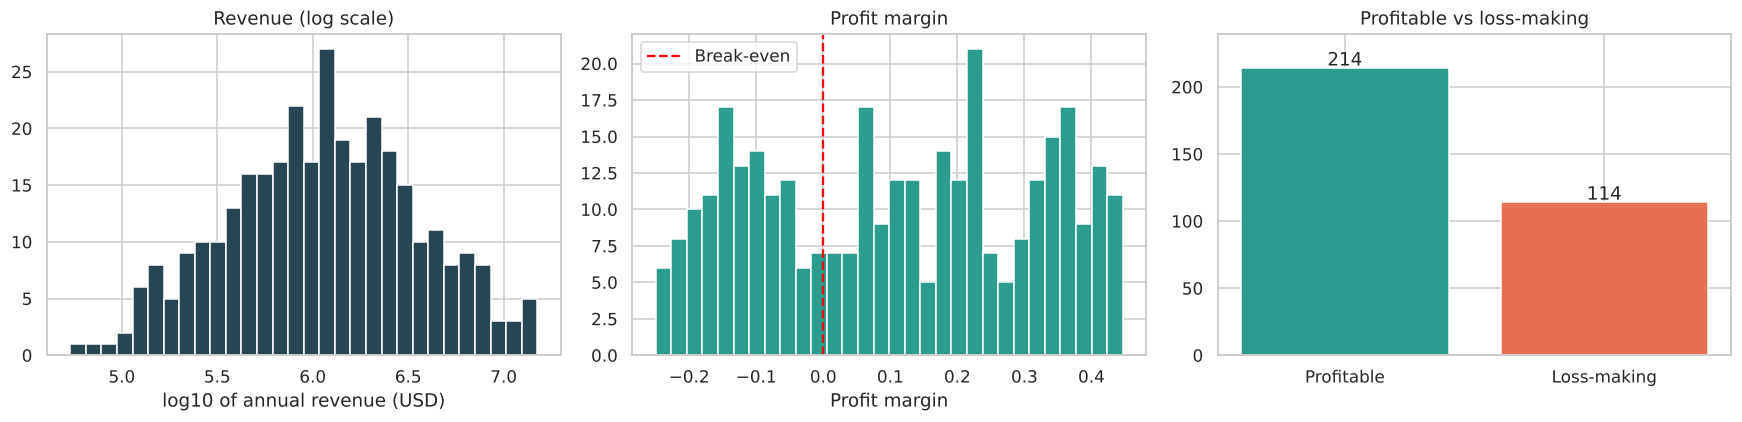

Loss-making firms: 114 of 328 (34.8%)


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(np.log10(df["annual_revenue"]), bins=30, color=PALETTE[0], edgecolor="white")
axes[0].set_xlabel("log10 of annual revenue (USD)")
axes[0].set_title("Revenue (log scale)")

axes[1].hist(df["profit_margin"], bins=30, color=PALETTE[1], edgecolor="white")
axes[1].axvline(0, color="red", linestyle="--", linewidth=1.5, label="Break-even")
axes[1].set_xlabel("Profit margin")
axes[1].set_title("Profit margin")
axes[1].legend()

status = (df["annual_profit"] < 0).map({True: "Loss-making", False: "Profitable"}).value_counts()
status_colors = {"Loss-making": PALETTE[4], "Profitable": PALETTE[1]}
axes[2].bar(status.index, status.values, color=[status_colors[label] for label in status.index])
for i, v in enumerate(status.values):
    axes[2].text(i, v + 2, str(v), ha="center")
axes[2].set_ylim(0, status.max() * 1.12)
axes[2].set_title("Profitable vs loss-making")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_revenue_profit.png", bbox_inches="tight")
plt.show()
loss_n = int((df["annual_profit"] < 0).sum())
print(f"Loss-making firms: {loss_n} of {len(df)} ({loss_n / len(df):.1%})")

### 3.3 Company size

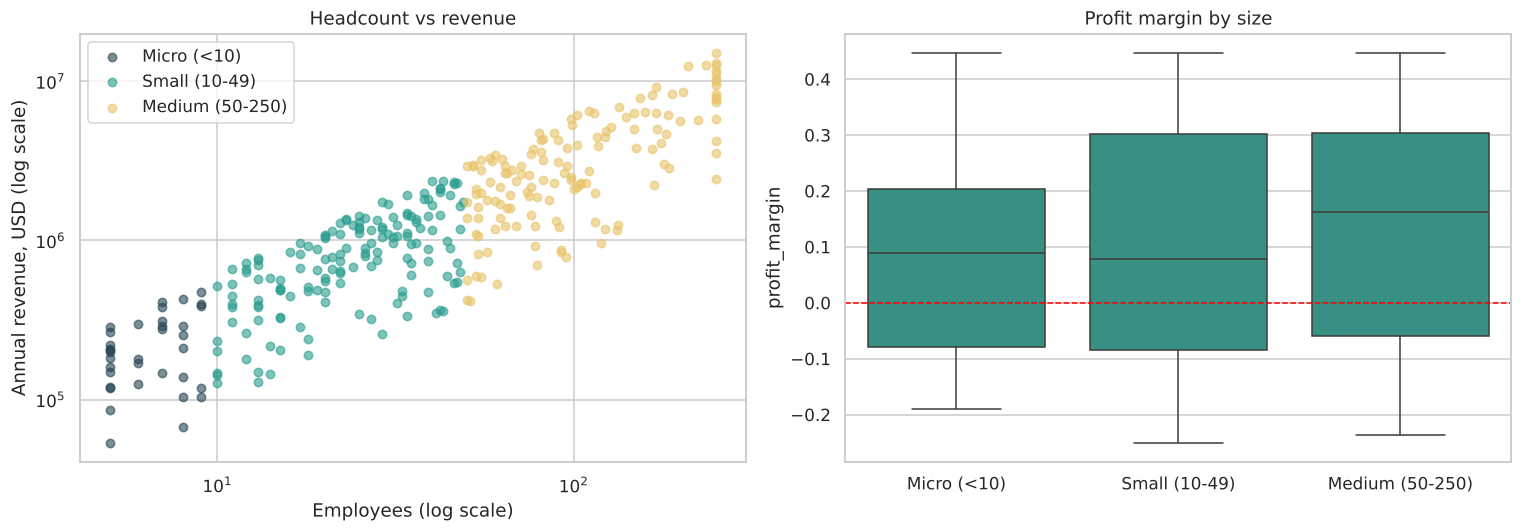

,firms,median_revenue,median_margin
sme_size,,,
Micro (<10),35,205015.94,0.088
Small (10-49),153,767544.70,0.079
Medium (50-250),140,2888786.20,0.162


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for size, colour in zip(SIZE_ORDER, PALETTE[:3]):
    part = df[df["sme_size"] == size]
    axes[0].scatter(part["employee_count"], part["annual_revenue"], s=30, alpha=0.6, color=colour, label=size)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Employees (log scale)")
axes[0].set_ylabel("Annual revenue, USD (log scale)")
axes[0].set_title("Headcount vs revenue")
axes[0].legend()

sns.boxplot(data=df, x="sme_size", y="profit_margin", order=SIZE_ORDER, color=PALETTE[1], ax=axes[1])
axes[1].axhline(0, color="red", linestyle="--", linewidth=1)
axes[1].set_xlabel("")
axes[1].set_title("Profit margin by size")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_size_segments.png", bbox_inches="tight")
plt.show()
(df.groupby("sme_size")
   .agg(firms=("sme_id", "count"), median_revenue=("annual_revenue", "median"), median_margin=("profit_margin", "median"))
   .reindex(SIZE_ORDER).round(3))

### 3.4 Leverage and loans

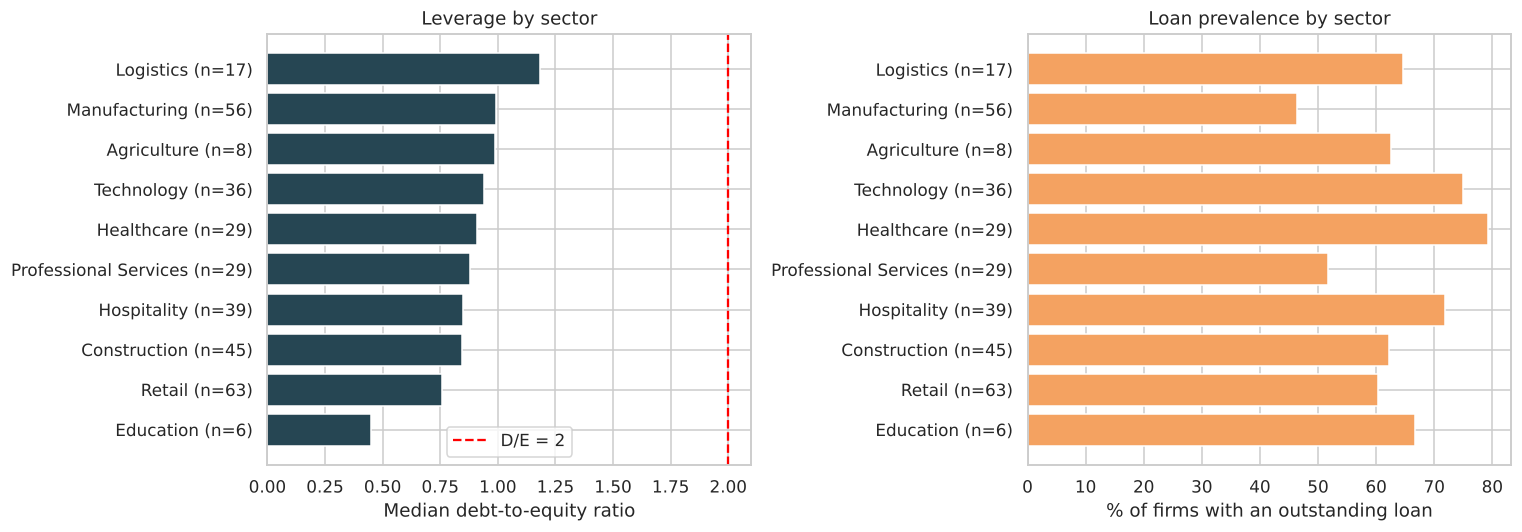

Debt-to-equity above 2: 60 firms (18.3%). Above 3: 21 firms (6.4%).


,firms,median_de,pct_with_loan
industry_sector,,,
Retail,63,0.76,60.32
Manufacturing,56,0.99,46.43
Construction,45,0.84,62.22
Hospitality,39,0.85,71.79
Technology,36,0.94,75.00
Healthcare,29,0.91,79.31
Professional Services,29,0.88,51.72
Logistics,17,1.18,64.71
Agriculture,8,0.99,62.50


In [21]:
by_sector = df.groupby("industry_sector").agg(
    firms=("sme_id", "count"),
    median_de=("debt_to_equity_ratio", "median"),
    pct_with_loan=("has_loan_outstanding", lambda s: (s == "Yes").mean() * 100),
).sort_values("median_de")
labels = [f"{s} (n={n})" for s, n in zip(by_sector.index, by_sector["firms"])]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(labels, by_sector["median_de"], color=PALETTE[0])
axes[0].axvline(2, color="red", linestyle="--", label="D/E = 2")
axes[0].set_xlabel("Median debt-to-equity ratio")
axes[0].set_title("Leverage by sector")
axes[0].legend()
axes[1].barh(labels, by_sector["pct_with_loan"], color=PALETTE[3])
axes[1].set_xlabel("% of firms with an outstanding loan")
axes[1].set_title("Loan prevalence by sector")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_leverage_loans.png", bbox_inches="tight")
plt.show()
n_de2 = int((df["debt_to_equity_ratio"] > 2).sum())
n_de3 = int((df["debt_to_equity_ratio"] > 3).sum())
print(f"Debt-to-equity above 2: {n_de2} firms ({n_de2 / len(df):.1%}). Above 3: {n_de3} firms ({n_de3 / len(df):.1%}).")
by_sector.sort_values("firms", ascending=False).round(2)

### 3.5 Digital adoption

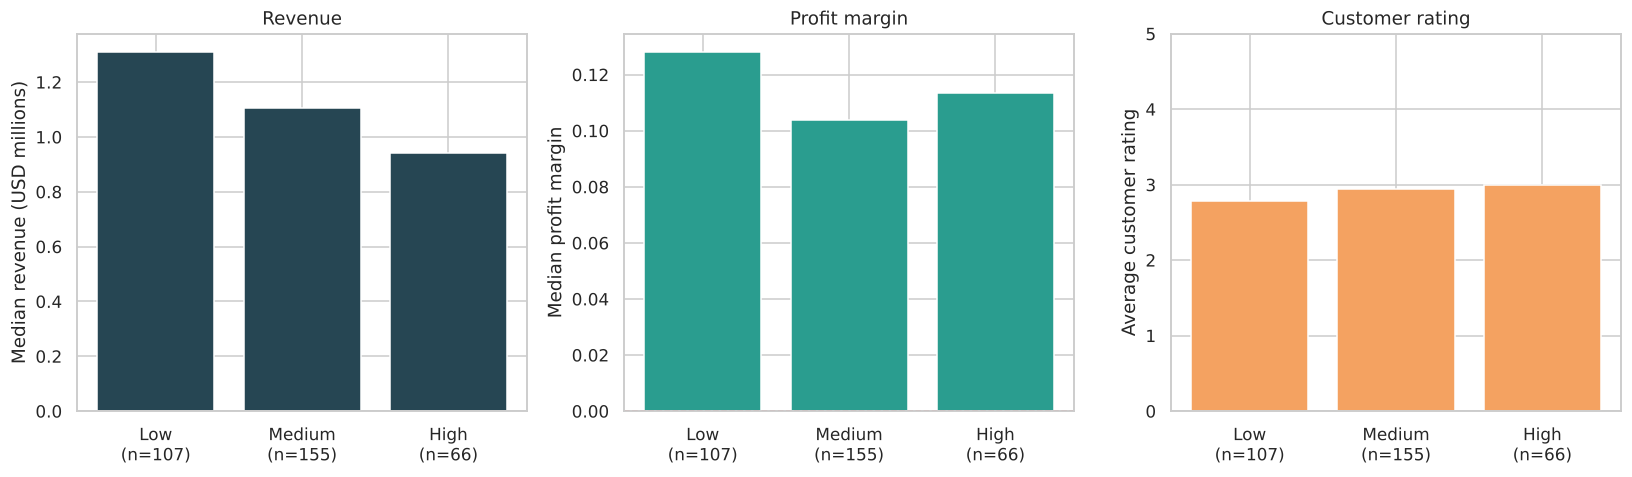

Kruskal-Wallis test of profit margin across the three adoption levels: p = 0.45


,firms,median_revenue,median_margin,avg_rating
digital_adoption_level,,,,
Low,107,1311158.90,0.128,2.783
Medium,155,1104340.58,0.104,2.946
High,66,941554.72,0.113,3.002


In [22]:
ADOPT_ORDER = ["Low", "Medium", "High"]
adopt = (df.groupby("digital_adoption_level")
           .agg(firms=("sme_id", "count"), median_revenue=("annual_revenue", "median"),
                median_margin=("profit_margin", "median"), avg_rating=("avg_customer_rating", "mean"))
           .reindex(ADOPT_ORDER))
labels = [f"{a}\n(n={n})" for a, n in zip(adopt.index, adopt["firms"])]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].bar(labels, adopt["median_revenue"] / 1e6, color=PALETTE[0])
axes[0].set_ylabel("Median revenue (USD millions)")
axes[0].set_title("Revenue")
axes[1].bar(labels, adopt["median_margin"], color=PALETTE[1])
axes[1].axhline(0, color="red", linestyle="--", linewidth=1)
axes[1].set_ylabel("Median profit margin")
axes[1].set_title("Profit margin")
axes[2].bar(labels, adopt["avg_rating"], color=PALETTE[3])
axes[2].set_ylim(0, 5)
axes[2].set_ylabel("Average customer rating")
axes[2].set_title("Customer rating")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_digital_adoption.png", bbox_inches="tight")
plt.show()

groups = [g["profit_margin"].to_numpy() for _, g in df.groupby("digital_adoption_level")]
kw = stats.kruskal(*groups)
print(f"Kruskal-Wallis test of profit margin across the three adoption levels: p = {kw.pvalue:.2f}")
adopt.round(3)

### 3.6 Correlations

Spearman correlation, because revenue, assets and followers are heavily skewed.

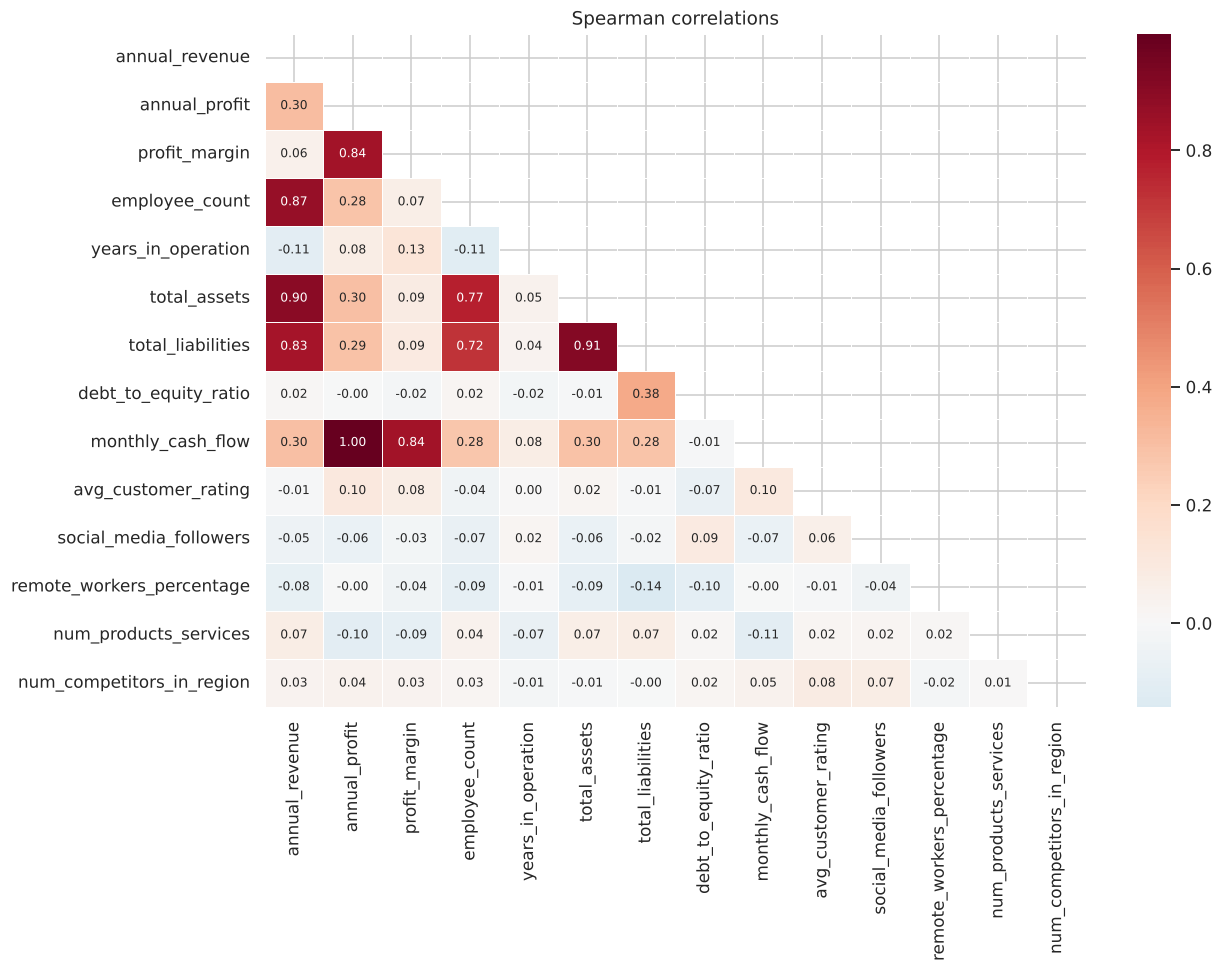

In [23]:
num_cols = ["annual_revenue", "annual_profit", "profit_margin", "employee_count", "years_in_operation",
            "total_assets", "total_liabilities", "debt_to_equity_ratio", "monthly_cash_flow",
            "avg_customer_rating", "social_media_followers", "remote_workers_percentage",
            "num_products_services", "num_competitors_in_region"]
corr = df[num_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5,
            annot_kws={"size": 8}, ax=ax)
ax.set_title("Spearman correlations")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_correlation.png", bbox_inches="tight")
plt.show()

### 3.7 What the exploration shows

The lines below are calculated from the data.

In [24]:
firms_per_sector = df["industry_sector"].value_counts()
large_sectors = firms_per_sector[firms_per_sector >= 15].index
small_sectors = firms_per_sector[firms_per_sector < 15]
de_large = (df[df["industry_sector"].isin(large_sectors)]
              .groupby("industry_sector")["debt_to_equity_ratio"].median().sort_values())
rho = df["employee_count"].corr(df["annual_revenue"], method="spearman")
margin_by_adoption = df.groupby("digital_adoption_level")["profit_margin"].median().reindex(ADOPT_ORDER)

print(f"Loss-making firms: {loss_n} of {len(df)} ({loss_n / len(df):.1%})")
print(f"Spearman correlation between employees and revenue: {rho:.2f}")
print(f"Median debt-to-equity across sectors with at least 15 firms: "
      f"highest {de_large.index[-1]} ({de_large.iloc[-1]:.2f}), lowest {de_large.index[0]} ({de_large.iloc[0]:.2f})")
print("Sectors too small to compare: " + ", ".join(f"{s} (n={n})" for s, n in small_sectors.items()))
print("Median profit margin by digital adoption: " +
      ", ".join(f"{k} {v:.3f}" for k, v in margin_by_adoption.items()) + f" (Kruskal-Wallis p = {kw.pvalue:.2f})")

# Two gaps that look like findings in the charts. Test them before believing them.
de_groups = [g["debt_to_equity_ratio"].to_numpy()
             for _, g in df[df["industry_sector"].isin(large_sectors)].groupby("industry_sector")]
kw_de = stats.kruskal(*de_groups)
kw_size = stats.kruskal(*[g["profit_margin"].to_numpy() for _, g in df.groupby("sme_size")])
margin_by_size = df.groupby("sme_size")["profit_margin"].median().reindex(SIZE_ORDER)
print(f"Debt-to-equity across the {len(large_sectors)} larger sectors: Kruskal-Wallis p = {kw_de.pvalue:.2f}")
print("Median profit margin by size: " + ", ".join(f"{k} {v:.3f}" for k, v in margin_by_size.items()) +
      f" (Kruskal-Wallis p = {kw_size.pvalue:.2f})")

Loss-making firms: 114 of 328 (34.8%)
Spearman correlation between employees and revenue: 0.87
Median debt-to-equity across sectors with at least 15 firms: highest Logistics (1.18), lowest Retail (0.76)
Sectors too small to compare: Agriculture (n=8), Education (n=6)
Median profit margin by digital adoption: Low 0.128, Medium 0.104, High 0.113 (Kruskal-Wallis p = 0.45)
Debt-to-equity across the 8 larger sectors: Kruskal-Wallis p = 0.98
Median profit margin by size: Micro (<10) 0.088, Small (10-49) 0.079, Medium (50-250) 0.162 (Kruskal-Wallis p = 0.50)


## 4. Build features

I add financial ratios, flags and encodings. I also build a transparent stress score from two signals: a loss and high leverage.

In [25]:
fe = df.copy()

# Financial ratios
fe["asset_to_revenue_ratio"] = fe["total_assets"] / fe["annual_revenue"]
fe["liability_to_asset_ratio"] = fe["total_liabilities"] / fe["total_assets"]
fe["revenue_per_employee"] = fe["annual_revenue"] / fe["employee_count"]
fe["profit_per_employee"] = fe["annual_profit"] / fe["employee_count"]
fe["cash_flow_to_revenue"] = fe["monthly_cash_flow"] * 12 / fe["annual_revenue"]
fe["revenue_maturity_ratio"] = fe["annual_revenue"] / fe["years_in_operation"].clip(lower=1)

# Log versions of the skewed columns
for col in ["annual_revenue", "total_assets", "total_liabilities", "social_media_followers",
            "loan_amount", "revenue_per_employee", "revenue_maturity_ratio"]:
    fe[f"log_{col}"] = np.log1p(fe[col])

# Encodings
fe["digital_adoption_enc"] = fe["digital_adoption_level"].map({"Low": 0, "Medium": 1, "High": 2})
for source, target in [("website_exists", "website_bin"), ("export_products", "export_bin"),
                       ("has_loan_outstanding", "loan_bin"), ("sustainability_certified", "sustainability_bin"),
                       ("founded_during_recession", "recession_founded")]:
    fe[target] = (fe[source] == "Yes").astype(int)
fe["sustainability_unknown"] = (fe["sustainability_certified"] == "Unknown").astype(int)
fe["sme_size_enc"] = fe["sme_size"].map({"Micro (<10)": 0, "Small (10-49)": 1, "Medium (50-250)": 2})

print(f"{fe.shape[1]} columns after feature engineering")
fe[["asset_to_revenue_ratio", "liability_to_asset_ratio", "revenue_per_employee", "cash_flow_to_revenue"]].describe().round(2)

56 columns after feature engineering


,asset_to_revenue_ratio,liability_to_asset_ratio,revenue_per_employee,cash_flow_to_revenue
count,328.00,328.00,328.00,328.00
mean,2.59,0.45,33466.62,0.11
std,1.18,0.20,15015.76,0.21
min,0.54,0.10,8062.41,-0.28
25%,1.52,0.28,21653.05,-0.08
50%,2.47,0.46,33304.23,0.12
75%,3.44,0.63,45586.98,0.26
max,5.51,0.79,59960.58,0.57


### Stress score

- **Loss-making:** annual profit below zero.
- **High leverage:** debt-to-equity above 2. This is a rule of thumb I chose. A lender would set its own limit.
- **Tier:** Green has neither signal, Amber has one, Red has both.

I leave out a "negative cash flow" signal. The next cell checks why.

In [26]:
fe["loss_making"] = (fe["annual_profit"] < 0).astype(int)
fe["high_leverage"] = (fe["debt_to_equity_ratio"] > 2).astype(int)
fe["negative_cash_flow"] = (fe["monthly_cash_flow"] < 0).astype(int)

same_signal = bool((fe["loss_making"] == fe["negative_cash_flow"]).all())
print(f"Negative cash flow matches loss-making in every row: {same_signal}")

fe["stress_points"] = fe["loss_making"] + fe["high_leverage"]
fe["stress_tier"] = fe["stress_points"].map({0: "Green", 1: "Amber", 2: "Red"})
tier_counts = fe["stress_tier"].value_counts().reindex(["Green", "Amber", "Red"])
pd.DataFrame({"firms": tier_counts, "share": (tier_counts / len(fe)).round(3)})

Negative cash flow matches loss-making in every row: True


,firms,share
stress_tier,,
Green,178,0.543
Amber,126,0.384
Red,24,0.073


In this dataset `monthly_cash_flow` is built from `annual_profit`, so the two always agree. Counting both would count each loss twice. Real cash flow and profit usually differ, and a real score should use both.

## 5. Modelling: can we predict which SMEs make a loss?

**Target:** `loss_making`, meaning annual profit below zero.

**Inputs:** balance-sheet and non-financial features. I leave out every column built from profit (`annual_profit`, `profit_margin`, `monthly_cash_flow`, `cash_flow_to_revenue`, `profit_per_employee`) because the target comes from profit. Including them lets the model read the answer.

**Evaluation:** 5-fold cross-validation repeated 10 times, scored by ROC-AUC. A score of 0.5 is no better than chance. With a few hundred firms a single train-test split is noisy, so I report the spread across all 50 folds.

In [27]:
model_df = pd.get_dummies(fe, columns=["industry_sector", "business_structure"], drop_first=True, dtype=int)

LEAKY = ["annual_profit", "profit_margin", "monthly_cash_flow", "cash_flow_to_revenue",
         "profit_per_employee", "negative_cash_flow", "stress_points"]
numeric = ["employee_count", "years_in_operation", "num_products_services", "avg_customer_rating",
           "remote_workers_percentage", "num_competitors_in_region", "debt_to_equity_ratio",
           "liability_to_asset_ratio", "asset_to_revenue_ratio", "log_annual_revenue", "log_total_assets",
           "log_total_liabilities", "log_social_media_followers", "log_loan_amount",
           "log_revenue_per_employee", "log_revenue_maturity_ratio"]
flags = ["digital_adoption_enc", "website_bin", "export_bin", "loan_bin", "sustainability_bin",
         "sustainability_unknown", "recession_founded", "sme_size_enc"]
dummies = [c for c in model_df.columns if c.startswith(("industry_sector_", "business_structure_"))]

FEATURES = numeric + flags + dummies
assert set(FEATURES).isdisjoint(LEAKY)
X = model_df[FEATURES].astype(float)
y = model_df["loss_making"]
print(f"{len(FEATURES)} features, {len(y)} firms, {y.mean():.1%} loss-making")

37 features, 328 firms, 34.8% loss-making


In [28]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)


def make_pipeline(model, scale=False):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)


candidates = {
    "Baseline (class prior)": make_pipeline(DummyClassifier(strategy="prior")),
    "Logistic regression": make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"), scale=True),
    "Random forest": make_pipeline(RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=5,
                                                          class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)),
    "Gradient boosting": make_pipeline(GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=0.05,
                                                                  subsample=0.8, random_state=SEED)),
}

rows = []
for name, pipe in candidates.items():
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="roc_auc")
    rows.append({"model": name, "mean_auc": scores.mean(), "std_auc": scores.std(),
                 "lowest_fold": scores.min(), "highest_fold": scores.max()})
results = pd.DataFrame(rows).set_index("model")
results.round(3)

,mean_auc,std_auc,lowest_fold,highest_fold
model,,,,
Baseline (class prior),0.500,0.000,0.500,0.500
Logistic regression,0.525,0.056,0.441,0.711
Random forest,0.549,0.063,0.398,0.676
Gradient boosting,0.551,0.066,0.392,0.686


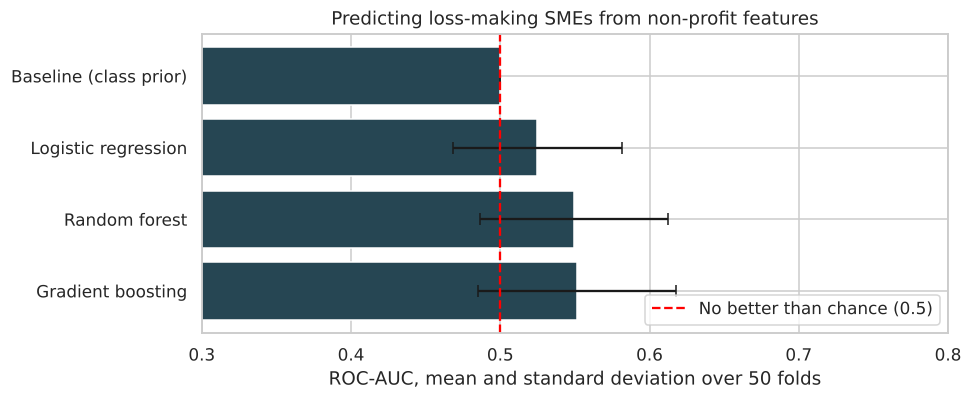

In [29]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(results.index[::-1], results["mean_auc"][::-1], xerr=results["std_auc"][::-1], color=PALETTE[0], capsize=4)
ax.axvline(0.5, color="red", linestyle="--", label="No better than chance (0.5)")
ax.set_xlim(0.3, 0.8)
ax.set_xlabel("ROC-AUC, mean and standard deviation over 50 folds")
ax.set_title("Predicting loss-making SMEs from non-profit features")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_model_cv.png", bbox_inches="tight")
plt.show()

### Reading the model results

No model does much better than chance. Gradient boosting has the highest mean AUC (0.551), followed by the other two at 0.549 and 0.525. A model with no information scores 0.500.

The spread matters as much as the average. Across the 50 folds the standard deviation is 0.06 to 0.07 for each model, and single folds range from 0.39 to 0.71. That spread is larger than the gap to chance, so I read these scores as no usable signal. A lender could not screen applicants with these models.

I expected this. In the data generator, profit margin is drawn at random, so loss status does not depend on the other fields.

The check below shows how easy it is to get a perfect-looking score by mistake. `profit_margin` is the target restated, because a negative margin means a loss.

### What happens if profit-based columns are included

This is the mistake the earlier version of this project made. The check below adds one profit-based column.

In [30]:
cv_short = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
logit = make_pipeline(LogisticRegression(max_iter=2000), scale=True)
auc_clean = cross_val_score(logit, X, y, cv=cv_short, scoring="roc_auc").mean()
X_leaky = model_df[FEATURES + ["profit_margin"]].astype(float)
auc_leaky = cross_val_score(logit, X_leaky, y, cv=cv_short, scoring="roc_auc").mean()
print(f"Logistic regression without profit_margin: AUC {auc_clean:.3f}")
print(f"Logistic regression with profit_margin:    AUC {auc_leaky:.3f}")

Logistic regression without profit_margin: AUC 0.513
Logistic regression with profit_margin:    AUC 0.995


### Which variables relate to losses at all?

Since the models find little, I test each variable on its own. With 19 tests, about one raw p-value below 0.05 is expected by chance alone, so I also report p-values adjusted for multiple testing (Benjamini-Hochberg).

In [31]:
screen = []
for col in ["industry_sector", "business_structure", "digital_adoption_level", "website_exists", "export_products",
            "has_loan_outstanding", "sustainability_certified", "founded_during_recession", "sme_size"]:
    table = pd.crosstab(fe[col], fe["loss_making"])
    _, p, _, expected = stats.chi2_contingency(table)
    screen.append({"variable": col, "test": "chi-square", "p_value": p,
                   "note": "some expected counts below 5" if (expected < 5).any() else ""})
for col in ["employee_count", "years_in_operation", "num_products_services", "avg_customer_rating",
            "remote_workers_percentage", "num_competitors_in_region", "annual_revenue", "total_assets",
            "debt_to_equity_ratio", "social_media_followers"]:
    _, p = stats.mannwhitneyu(fe.loc[fe["loss_making"] == 1, col], fe.loc[fe["loss_making"] == 0, col],
                              alternative="two-sided")
    screen.append({"variable": col, "test": "Mann-Whitney U", "p_value": p, "note": ""})

screen = pd.DataFrame(screen).sort_values("p_value").reset_index(drop=True)
m = len(screen)
ranked = screen["p_value"] * m / (screen.index + 1)
screen["adjusted_p"] = ranked[::-1].cummin()[::-1].clip(upper=1)
print(f"{m} tests. Raw p below 0.05: {(screen['p_value'] < 0.05).sum()}. Adjusted p below 0.05: {(screen['adjusted_p'] < 0.05).sum()}.")
screen.round(3)

19 tests. Raw p below 0.05: 1. Adjusted p below 0.05: 0.


,variable,test,p_value,note,adjusted_p
0,num_products_services,Mann-Whitney U,0.039,,0.468
1,debt_to_equity_ratio,Mann-Whitney U,0.080,,0.468
2,num_competitors_in_region,Mann-Whitney U,0.126,,0.468
3,social_media_followers,Mann-Whitney U,0.159,,0.468
4,sme_size,chi-square,0.164,,0.468
5,employee_count,Mann-Whitney U,0.166,,0.468
6,industry_sector,chi-square,0.190,some expected counts below 5,0.468
7,total_assets,Mann-Whitney U,0.198,,0.468
8,avg_customer_rating,Mann-Whitney U,0.224,,0.468
9,years_in_operation,Mann-Whitney U,0.251,,0.468


### Reading the screen

Of 19 variables, 1 reached a raw p-value below 0.05: `num_products_services` (p = 0.039). With 19 tests, about one such result is expected by chance. After adjustment for multiple testing, none comes close (smallest adjusted p = 0.47).

I found no evidence that any variable relates to losses. With 328 firms the screen can only detect fairly large effects. The sector and sustainability tests also have some small cells, so they are weaker than the rest.

## 6. Risk tiers and dashboard

The tiers come from the stress score in section 4. They are rules, not model predictions.

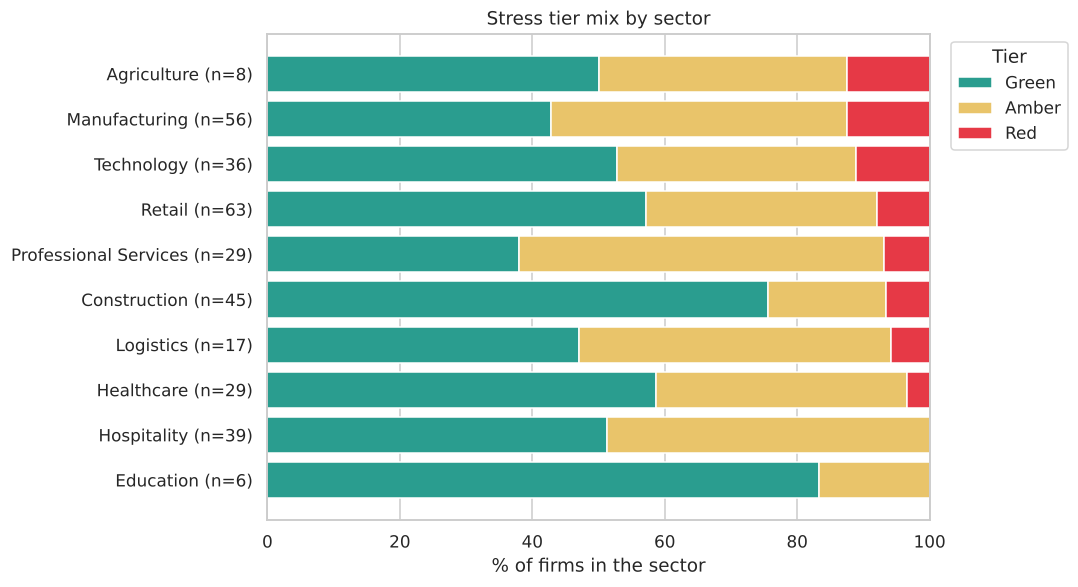

In [32]:
TIERS = ["Green", "Amber", "Red"]
counts = pd.crosstab(fe["industry_sector"], fe["stress_tier"]).reindex(columns=TIERS, fill_value=0)
share = counts.div(counts.sum(axis=1), axis=0) * 100
share = share.sort_values("Red")

fig, ax = plt.subplots(figsize=(10, 5.5))
left = np.zeros(len(share))
for tier in TIERS:
    ax.barh(range(len(share)), share[tier], left=left, color=TIER_COLORS[tier], label=tier)
    left += share[tier].to_numpy()
ax.set_yticks(range(len(share)))
ax.set_yticklabels([f"{s} (n={counts.loc[s].sum()})" for s in share.index])
ax.set_xlabel("% of firms in the sector")
ax.set_title("Stress tier mix by sector")
ax.legend(title="Tier", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_tier_by_sector.png", bbox_inches="tight")
plt.show()

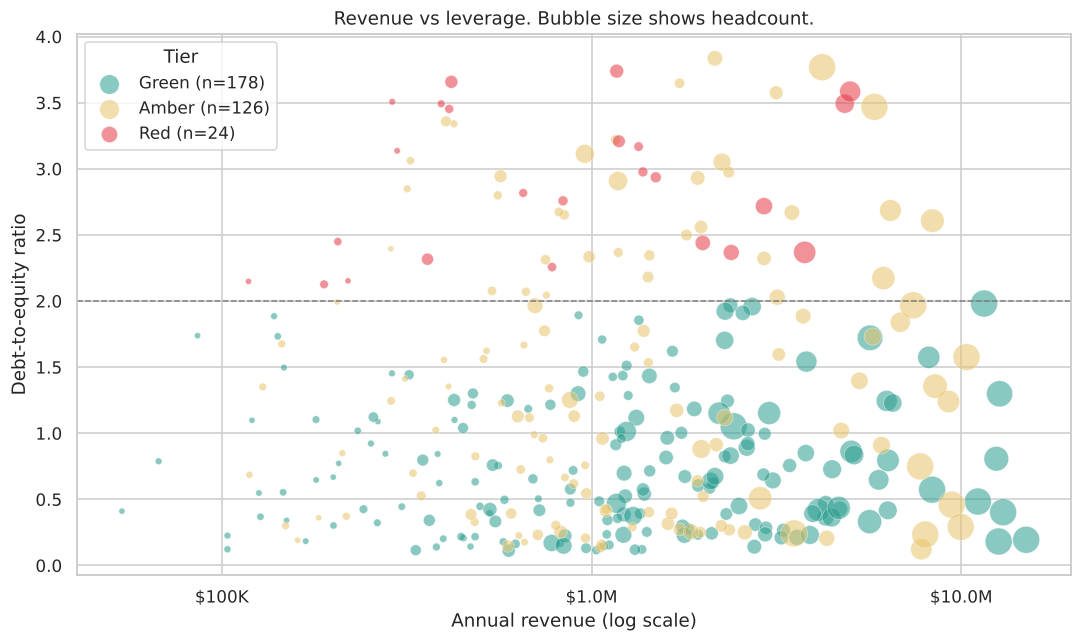

In [33]:
fig, ax = plt.subplots(figsize=(10, 6))
for tier in TIERS:
    part = fe[fe["stress_tier"] == tier]
    ax.scatter(part["annual_revenue"], part["debt_to_equity_ratio"], s=part["employee_count"] * 1.2 + 10,
               alpha=0.55, color=TIER_COLORS[tier], label=f"{tier} (n={len(part)})", edgecolor="white", linewidth=0.4)
ax.axhline(2, color="grey", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v / 1e6:.1f}M" if v >= 1e6 else f"${v / 1e3:.0f}K"))
ax.set_xlabel("Annual revenue (log scale)")
ax.set_ylabel("Debt-to-equity ratio")
ax.set_title("Revenue vs leverage. Bubble size shows headcount.")
ax.legend(title="Tier")
plt.tight_layout()
plt.savefig(FIG_DIR / "09_revenue_vs_leverage.png", bbox_inches="tight")
plt.show()

In [34]:
summary = (fe.groupby("stress_tier")
             .agg(firms=("sme_id", "count"), median_revenue=("annual_revenue", "median"),
                  median_margin=("profit_margin", "median"), median_de=("debt_to_equity_ratio", "median"),
                  pct_with_loan=("loan_bin", lambda s: s.mean() * 100), avg_rating=("avg_customer_rating", "mean"))
             .reindex(TIERS).round(2))
summary

,firms,median_revenue,median_margin,median_de,pct_with_loan,avg_rating
stress_tier,,,,,,
Green,178,1223917.71,0.23,0.64,64.04,2.98
Amber,126,1061738.60,-0.09,1.23,62.70,2.84
Red,24,809763.92,-0.11,2.88,50.00,2.70


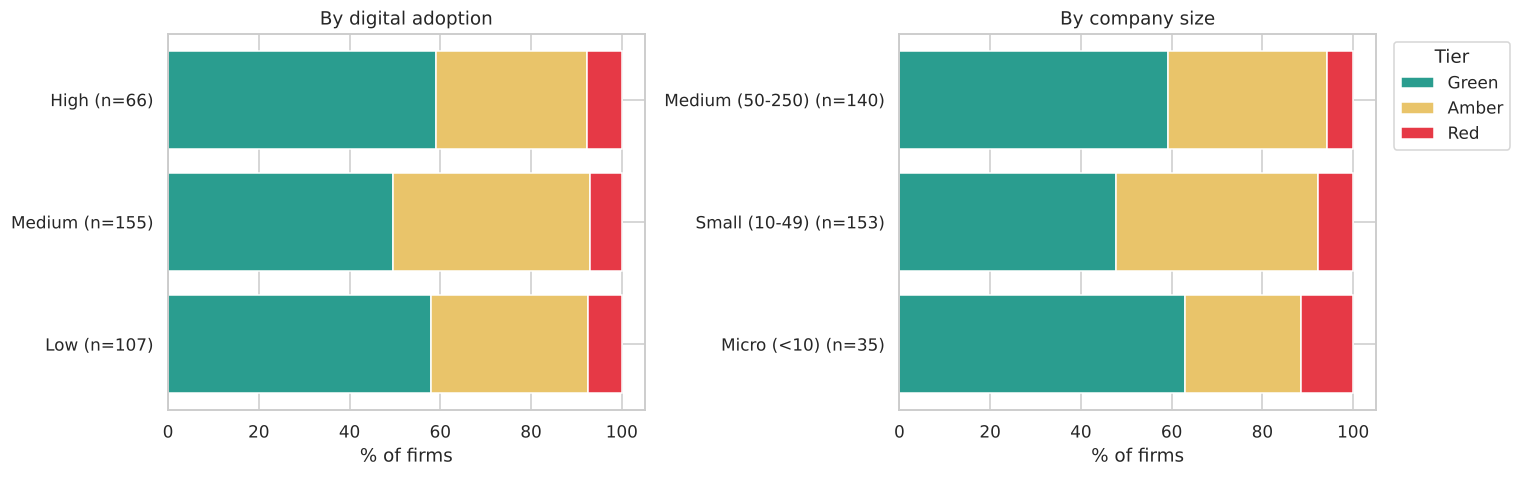

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col, order, title in [(axes[0], "digital_adoption_level", ADOPT_ORDER, "By digital adoption"),
                              (axes[1], "sme_size", SIZE_ORDER, "By company size")]:
    table = pd.crosstab(fe[col], fe["stress_tier"]).reindex(index=order, columns=TIERS, fill_value=0)
    pct = table.div(table.sum(axis=1), axis=0) * 100
    left = np.zeros(len(pct))
    for tier in TIERS:
        ax.barh(range(len(pct)), pct[tier], left=left, color=TIER_COLORS[tier], label=tier)
        left += pct[tier].to_numpy()
    ax.set_yticks(range(len(pct)))
    ax.set_yticklabels([f"{o} (n={table.loc[o].sum()})" for o in order])
    ax.set_xlabel("% of firms")
    ax.set_title(title)
axes[1].legend(title="Tier", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "10_tier_by_segment.png", bbox_inches="tight")
plt.show()

### Reading the tiers

178 firms (54.3%) are Green, 126 (38.4%) are Amber and 24 (7.3%) are Red.

The gaps between tiers in median margin and debt-to-equity are built into the definition, so they are not findings. Revenue, loan share and customer rating are not part of the definition. Red firms have lower median revenue ($0.81M against $1.22M for Green) and a lower average rating (2.70 against 2.98). Only 24 firms are Red and I did not test these gaps, so treat them as description.

Among sectors with at least 15 firms, the Red share runs from 0.0% in Hospitality (0 of 39) to 12.5% in Manufacturing (7 of 56). These shares rest on small counts and I did not test them. Agriculture (8 firms) and Education (6) are too small to read.

## 7. Findings and recommendations

### 7.1 What the data shows

| # | Finding | Weight |
|---|---------|--------|
| 1 | 114 of 328 SMEs (34.8%) made a loss. 60 firms (18.3%) have debt-to-equity above 2 and 21 (6.4%) are above 3. 24 firms (7.3%) have both a loss and debt-to-equity above 2. | Solid as a description of this sample. |
| 2 | Leverage does not differ by sector. Among the eight sectors with at least 15 firms, median debt-to-equity runs from 0.76 (Retail) to 1.18 (Logistics), but the difference is not significant (Kruskal-Wallis p = 0.98). | No evidence of a difference. |
| 3 | Digital adoption does not relate to profit margin. Median margin is 12.8%, 10.4% and 11.3% for Low, Medium and High adoption (p = 0.45). | No evidence of a link. |
| 4 | Larger firms earn more revenue. Median revenue is $0.21M for micro, $0.77M for small and $2.89M for medium firms. Headcount and revenue have a Spearman correlation of 0.87. | Solid, but the generator builds revenue from headcount, so it is expected. |
| 5 | Median margin is 8.8% for micro, 7.9% for small and 16.2% for medium firms. The medium-firm gap is not reliable (p = 0.50). | Do not act on it. |
| 6 | Non-profit features do not predict which firms make a loss. The best mean AUC is 0.551, against 0.500 for no information. | Solid for this data. |
| 7 | Adding a profit-based column raises AUC from 0.513 to 0.995. That is leakage. | A warning, not a result. |
| 8 | 14 data problems were logged. Examples: 274 rows in mixed date formats, 91 rows with inconsistent adoption spellings, 30 margins and 29 debt-to-equity values that disagree with the columns they come from. | Solid. |

### 7.2 Recommendations

1. **Use the scorecard for screening and monitoring, not forecasting.** It is easy to explain and check. A lender should set the two thresholds (a loss, debt-to-equity above 2) from its own credit policy.
2. **Do not rely on non-financial fields to predict losses.** On this evidence they carry no signal. With real data, test again with a time split, so the model predicts a later year from an earlier one.
3. **Store profit and cash flow separately.** Here cash flow is built from profit, so the two always agree and one adds nothing. Independent cash flow data would make a score stronger.
4. **Fix data quality at the source.** Calculated fields (years in operation, margin, debt-to-equity) should be calculated, not typed. Categories such as digital adoption need a fixed list and dates need one format.
5. **Do not draw sector conclusions from small groups.** Agriculture has 8 firms and Education has 6.

### 7.3 Limits

- **The data is synthetic.** Most patterns, and the lack of them, come from how the generator works.
- **One snapshot.** A loss in one year is not a default, and there is no time dimension to test against.
- **My thresholds.** The debt-to-equity limit of 2 is a rule of thumb I chose. Different limits would change the tier counts.
- **Exclusions.** I moved 17 records (4.9% of the 345 distinct firms) outside the SME definition. I did not test how the results change if they stay in.
- **Imputation.** Rating was filled with the median for 43 firms and remote share for 36. Both are flagged and I did not test the effect.
- **Date rule.** Slash dates are read as day first and dash dates as month first. That fits this file only.
- **Power.** With 328 firms the tests detect only fairly large effects. No evidence of a difference is not proof of none.

### 7.4 Next steps with real data

1. Replace the loss flag with an observed default or arrears flag.
2. Validate over time, training on earlier years and testing on later ones.
3. Add sector and macro indicators such as interest rates and sector growth.
4. Compare the scorecard thresholds against lender outcomes and recalibrate.

## 8. Save outputs

In [36]:
fe.to_csv(DATA_DIR / "sme_risk_scored.csv", index=False)
print("Saved data/sme_risk_scored.csv:", fe.shape)

Saved data/sme_risk_scored.csv: (328, 61)


The next cell saves every figure quoted in the written findings. The text in section 7 is built from this file, so each number can be traced back to the run.

In [37]:
REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(exist_ok=True)

red_by_sector = {s: {"firms": int(counts.loc[s].sum()), "red": int(counts.loc[s, "Red"]),
                     "red_pct": float(counts.loc[s, "Red"] / counts.loc[s].sum() * 100)} for s in counts.index}
facts = {
    "rows_raw": len(raw),
    "rows_clean": len(df),
    "issues": issue_log,
    "excluded_by_reason": excluded["exclusion_reason"].value_counts().to_dict(),
    "loss_n": loss_n,
    "de_above_2": n_de2,
    "de_above_3": n_de3,
    "tiers": {t: int(tier_counts[t]) for t in TIERS},
    "tier_summary": summary.reset_index().to_dict(orient="records"),
    "red_by_sector": red_by_sector,
    "spearman_employees_revenue": float(rho),
    "median_de_large_sectors": {k: float(v) for k, v in de_large.items()},
    "p_values": {"adoption_margin": float(kw.pvalue), "sector_de": float(kw_de.pvalue),
                 "size_margin": float(kw_size.pvalue)},
    "margin_by_adoption": {k: float(v) for k, v in margin_by_adoption.items()},
    "margin_by_size": {k: float(v) for k, v in margin_by_size.items()},
    "median_revenue_by_size": df.groupby("sme_size")["annual_revenue"].median().to_dict(),
    "firms_by_size": df["sme_size"].value_counts().to_dict(),
    "cv_results": results.reset_index().to_dict(orient="records"),
    "auc_without_profit_margin": float(auc_clean),
    "auc_with_profit_margin": float(auc_leaky),
    "screen_tests": int(len(screen)),
    "screen_raw_below_05": int((screen["p_value"] < 0.05).sum()),
    "screen_adjusted_below_05": int((screen["adjusted_p"] < 0.05).sum()),
    "screen_top": screen.iloc[0][["variable", "p_value", "adjusted_p"]].to_dict(),
    "screen_smallest_adjusted_p": float(screen["adjusted_p"].min()),
}
with open(REPORT_DIR / "key_figures.json", "w") as f:
    json.dump(facts, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved reports/key_figures.json")

Saved reports/key_figures.json
